# Heliox effects across exposure: Fig. 5 I-M, Supp. Fig. S7, Supp. Table S1

Reads one file, `exposure_course_data.pkl`, written by the data notebook.

| Panels | Question | Model |
|---|---|---|
| Fig. 5 I-M | Does the heliox effect change from early to late in a bird's exposure? | `metric ~ epoch * condition + day_number + (1 \| bird)` |
| Supp. Fig. S7 A-O | Is the first recording day different from later days? | `metric ~ epoch * condition * day_group + (1 \| bird)` |

In Fig. 5, a bird's syllables (songs for JSD) in one condition are ranked across all of
its recording days and cut into thirds. In S7 the ranking restarts each day.
Every effect is **Regair minus Heliox**, so a negative value means the feature is larger
under heliox. Tests are two-sided Wald z tests on the fitted fixed effects.

**Run order:** top to bottom. To rerun without a bird, set `EXCLUDE_BIRDS` in Cell 1;
every output file then gets a `_without_...` suffix.

In [2]:
# Cell 1: settings
import os, re, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
OUT_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'exposure_course_data.pkl')

EXCLUDE_BIRDS = []            # e.g. ['s_b1364h_25'] for the sensitivity rerun
MIN_N_PER_DAY = 60            # syllables in a day before it is split into three epochs (S7)
MIN_SONGS_PER_DAY = 8         # songs in a day before it is split into three epochs (S7)
EPOCHS = ['early', 'mid', 'late']

RUN_TAG = '' if not EXCLUDE_BIRDS else '_without_' + '_'.join(EXCLUDE_BIRDS)
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 16,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 13})

In [3]:
# Cell 2: which panel shows what
# Panel letters live only here. If the figure is rearranged, edit these two lists.
FIG5 = [  # letter, species, table in the pickle, column, title on the panel, name in the stats table
    ('I', 'starling',    'songs_jsd',             'jsd_song', 'JSD vs own-bird regair baseline', 'JSD vs own-bird regair baseline'),
    ('J', 'starling',    'syllables_starling',    'isi',      'ISI, starling (s)',               'Inter-syllable interval'),
    ('K', 'starling',    'syllables_starling',    'duration', 'Duration, starling (s)',          'Syllable duration'),
    ('L', 'zebra finch', 'syllables_zebra_finch', 'isi',      'ISI, zebra finch (s)',            'Inter-syllable interval'),
    ('M', 'zebra finch', 'syllables_zebra_finch', 'duration', 'Duration, zebra finch (s)',       'Syllable duration'),
]
S7 = [    # letter, species, kind of table, column
    ('A', 'zebra finch', 'syllables', 'isi'),      ('B', 'zebra finch', 'biosound', 'F1'),
    ('C', 'zebra finch', 'syllables', 'duration'), ('D', 'zebra finch', 'biosound', 'fund'),
    ('E', 'zebra finch', 'syllables', 'level_db'), ('F', 'zebra finch', 'biosound', 'meanS'),
    ('G', 'starling', 'syllables', 'isi'),         ('H', 'starling', 'biosound', 'F1'),
    ('I', 'starling', 'songs', 'tempo_roughness_ms'),
    ('J', 'starling', 'syllables', 'duration'),    ('K', 'starling', 'biosound', 'fund'),
    ('L', 'starling', 'songs', 'tempo_jump_rate'),
    ('M', 'starling', 'syllables', 'level_db'),    ('N', 'starling', 'biosound', 'meanS'),
    ('O', 'starling', 'biosound', 'entS'),
]
COLUMNS = {  # column: (axis label, name in the stats table, unit)
    'jsd_song':           ('JSD', 'JSD vs own-bird regair baseline', ''),
    'isi':                ('Inter-syllable interval (s)', 'Inter-syllable interval', 's'),
    'duration':           ('Duration (s)', 'Syllable duration', 's'),
    # amplitude: RMS level of the syllable in the recorded audio; spectral entropy: BioSound entS (0 to 1)
    'level_db':           ('Amplitude (dB)', 'Syllable amplitude', 'dB'),
    'entS':               ('Spectral entropy', 'Spectral entropy', ''),
    'F1':                 ('First formant (Hz)', 'First formant', 'Hz'),
    'fund':               ('Mean F0 (Hz)', 'Mean F0', 'Hz'),
    'meanS':              ('Spectral mean (Hz)', 'Spectral mean', 'Hz'),
    'tempo_roughness_ms': ('Roughness (ms)', 'Tempo roughness', 'ms'),
    'tempo_jump_rate':    ('Jump rate', 'Tempo jump rate', ''),
}

## 1. Load the data

In [4]:
# Cell 3: load, and drop any excluded bird from every table
with open(DATA_PATH, 'rb') as f:
    DATA = pickle.load(f)
meta = DATA.pop('meta')


def animal(name):
    # 's_b1364h_25' (syllable tables) and 's_b1364_25' (song tables) are one bird. Matching
    # on the name as written would drop it from some panels and leave it in others.
    return re.sub(r'(?<=\d)h(?=_)', '', str(name))


drop = {animal(b) for b in EXCLUDE_BIRDS}
everyone = set().union(*[set(df['bird'].map(animal)) for df in DATA.values()])
if drop - everyone:
    # a typo here would otherwise run the full dataset under a "_without_" file name
    raise ValueError(f'EXCLUDE_BIRDS names birds that are in no table: {sorted(drop - everyone)}')
DATA = {name: df[~df['bird'].map(animal).isin(drop)].copy() for name, df in DATA.items()}

print(f"data built {meta['created']}; excluded: {sorted(drop) or 'none'}")
for name, df in DATA.items():
    print(f'  {name:24s} {len(df):>7d} rows  {df["bird"].nunique()} birds')

data built 2026-10-11T12:10:56; excluded: none
  syllables_starling         95063 rows  6 birds
  syllables_zebra_finch      63728 rows  6 birds
  biosound_starling          98569 rows  6 birds
  biosound_zebra_finch       68392 rows  6 birds
  songs_tempo                 1568 rows  6 birds
  songs_jsd                   1418 rows  6 birds


## 2. Models

In [5]:
# Cell 4: the two models, and contrasts read off them
def fit_quietly(formula, data):
    # statsmodels warns whenever the bird variance is estimated at zero; whether a fit
    # converged is recorded in the stats table instead of printed here
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return smf.mixedlm(formula, data=data, groups=data['bird']).fit(reml=True)


def fit_epochs(df, column):
    """Fig. 5: thirds of order_norm (position across ALL of a bird's recording days in one
    condition). day_number is a covariate because it rises with position."""
    sub = df[['bird', 'condition', 'order_norm', 'day_number', column]].copy()
    sub = sub[np.isfinite(sub[column])]
    sub['epoch'] = pd.Categorical(pd.cut(sub['order_norm'], bins=np.linspace(0, 1, 4), labels=EPOCHS,
                                         include_lowest=True), categories=EPOCHS)
    sub['condition'] = pd.Categorical(sub['condition'], categories=['regair', 'heliox'])
    return fit_quietly(f"{column} ~ C(epoch, Treatment('early')) * condition + day_number", sub), sub


def fit_first_day(df, column, min_n):
    """S7: thirds of order_norm_day (position within the day), first day against later
    days. day_number is left out because day_group is made from it."""
    sub = df[['bird', 'condition', 'order_norm_day', 'first_day', 'n_day', column]].copy()
    sub = sub[np.isfinite(sub[column]) & (sub['n_day'] >= min_n)]
    sub['epoch'] = pd.Categorical(pd.cut(sub['order_norm_day'], bins=np.linspace(0, 1, 4), labels=EPOCHS,
                                         include_lowest=True), categories=EPOCHS)
    sub['day_group'] = pd.Categorical(np.where(sub['first_day'], 'first', 'later'), categories=['later', 'first'])
    sub['condition'] = pd.Categorical(sub['condition'], categories=['regair', 'heliox'])
    return fit_quietly(f"{column} ~ C(epoch, Treatment('early')) * condition * "
                       f"C(day_group, Treatment('later'))", sub), sub


def term(result, *pieces):
    """The one coefficient whose name contains every piece (interaction order varies)."""
    hits = [n for n in result.fe_params.index
            if all(p in n for p in pieces) and n.count(':') == len(pieces) - 1]
    if len(hits) != 1:
        raise KeyError(f'expected exactly 1 term matching {pieces}, found {hits}')
    return hits[0]


def effect_weights(result, epoch, day_group=None):
    """Weights on the fixed effects that give Regair minus Heliox in one cell: an epoch
    (Fig. 5 model) or an epoch x day group (S7 model)."""
    w = {term(result, 'condition[T.heliox]'): -1.0}
    if epoch != 'early':
        w[term(result, f'[T.{epoch}]', 'condition[T.heliox]')] = -1.0
    if day_group == 'first':
        w[term(result, 'condition[T.heliox]', '[T.first]')] = -1.0
        if epoch != 'early':
            w[term(result, f'[T.{epoch}]', 'condition[T.heliox]', '[T.first]')] = -1.0
    return w


def minus(wa, wb):
    """Weights for (effect a) minus (effect b); shared terms cancel."""
    out = dict(wa)
    for k, v in wb.items():
        out[k] = out.get(k, 0.0) - v
    return {k: v for k, v in out.items() if abs(v) > 1e-12}


def contrast(result, w):
    """Estimate, SE, 95% CI, Wald z and two-sided P for a weighted sum of fixed effects.
    Var(sum w_i b_i) = sum_i sum_j w_i w_j Cov(b_i, b_j)."""
    cov, fe, names = result.cov_params(), result.fe_params, list(w)
    est = sum(w[n] * fe[n] for n in names)
    var = 0.0
    for a in names:
        for b in names:
            var += w[a] * w[b] * cov.loc[a, b]
    se = np.sqrt(var)
    z = est / se
    # on the log scale, so P stays exact where 2 * sf(|z|) would underflow to 0
    log10_p = (np.log(2) + stats.norm.logsf(abs(z))) / np.log(10)
    return dict(estimate=est, SE=se, CI_low=est - 1.96 * se, CI_high=est + 1.96 * se,
                z=z, P=10 ** log10_p, log10_P=log10_p)


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

In [6]:
# Cell 5: fit every model once; the plots and the table both read from PANELS
PANELS = []
for letter, sp, table, column, title, feature in FIG5:
    result, used = fit_epochs(DATA[table], column)
    PANELS.append(dict(figure='Fig. 5', panel=letter, species=sp, column=column, title=title, feature=feature,
                       unit=COLUMNS[column][2], result=result, used=used))
for letter, sp, kind, column in S7:
    table = 'songs_tempo' if kind == 'songs' else f"{kind}_{sp.replace(' ', '_')}"
    result, used = fit_first_day(DATA[table], column, MIN_SONGS_PER_DAY if kind == 'songs' else MIN_N_PER_DAY)
    label, feature, unit = COLUMNS[column]
    PANELS.append(dict(figure='Supp. Fig. S7', panel=letter, species=sp, column=column, kind=kind,
                       title=f'{label}, {sp}', feature=feature, unit=unit, result=result, used=used))

# for p in PANELS:
#    # flag = '' if p['result'].converged else '   [did not converge]'
#     print(f"{p['figure']:14s}{p['panel']}  {p['species']:11s} {p['column']:19s} "
#           f"{p['used']['bird'].nunique()} birds, {len(p['used']):>6d} rows{flag}")

## 3. Fig. 5 I-M

Points are the model's Regair minus Heliox effect at each epoch with its 95% CI. Stars
under a point test that effect against zero; brackets test the change between epochs.

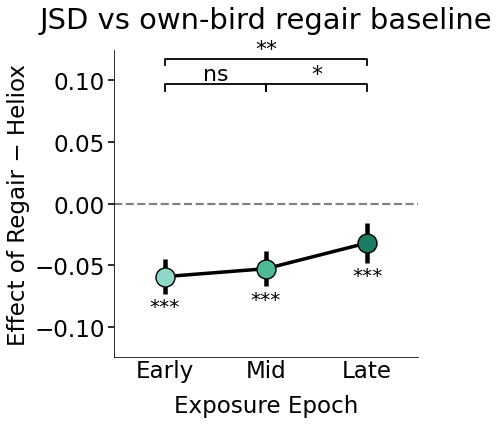

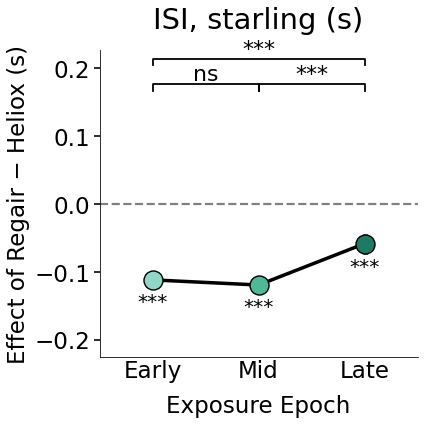

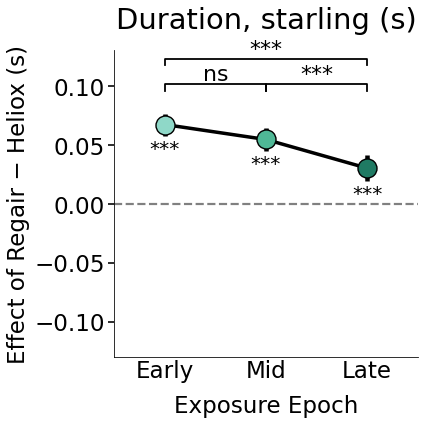

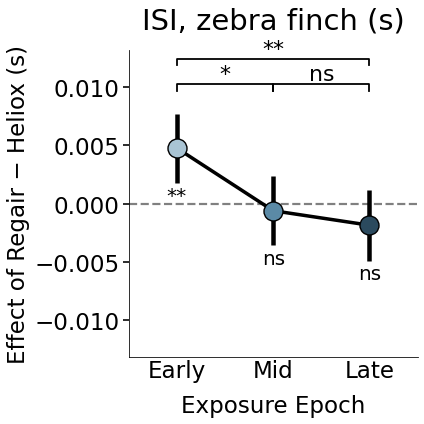

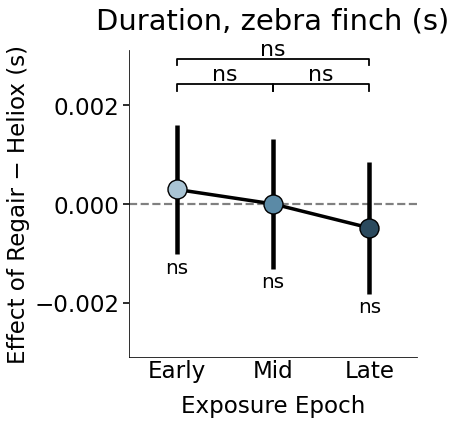

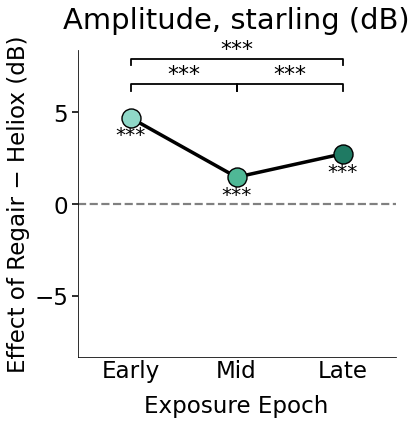

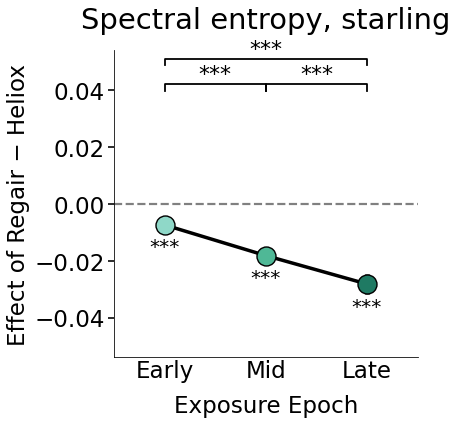

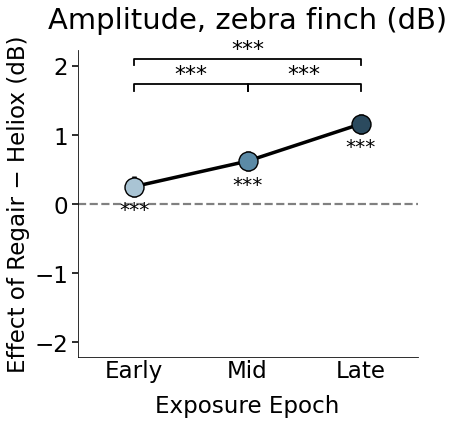

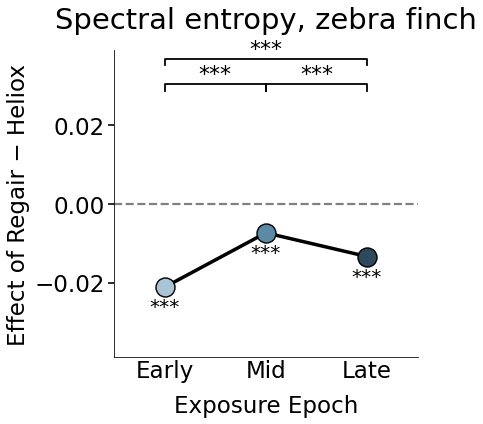

    species  feature     contrast estimate     SE      z        P stars  n_birds  n_obs  converged
   starling level_db        Early   4.6846 0.1187  39.47        0   ***        6  95063       True
   starling level_db          Mid   1.4508 0.1240  11.70  1.2e-31   ***        6  95063       True
   starling level_db         Late   2.7248 0.1385  19.68  3.4e-86   ***        6  95063       True
   starling level_db  Mid − Early  -3.2339 0.1641 -19.71  1.8e-86   ***        6  95063       True
   starling level_db   Late − Mid   1.2740 0.1655   7.70  1.4e-14   ***        6  95063       True
   starling level_db Late − Early  -1.9599 0.1735 -11.30  1.4e-29   ***        6  95063       True
   starling     entS        Early  -0.0074 0.0015  -4.92  8.7e-07   ***        6  98569       True
   starling     entS          Mid  -0.0182 0.0016 -11.49  1.5e-30   ***        6  98569       True
   starling     entS         Late  -0.0282 0.0018 -15.73  9.1e-56   ***        6  98569       True
   starlin

In [7]:
# Cell 6: Fig. 5 I-M, one file per panel
EPOCH_COLORS = {'starling': ['#8fd8c8', '#4fb896', '#1f7a63'],        # early, mid, late
                'zebra finch': ['#a9c4d4', '#5b8aa6', '#2b4a5e']}
X = dict(zip(EPOCHS, [0.0, 0.2, 0.4]))


def bracket(ax, x1, x2, y, height, p, fontsize):
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], lw=1.8, color='black')
    ax.text((x1 + x2) / 2, y + height, stars(p), ha='center', va='bottom', fontsize=fontsize)


def plot_epochs(ax, result, colors, title, ylabel):
    c = {e: contrast(result, effect_weights(result, e)) for e in EPOCHS}
    ax.plot([X[e] for e in EPOCHS], [c[e]['estimate'] for e in EPOCHS], '-', lw=3.5, color='black', zorder=4)
    for e, color in zip(EPOCHS, colors):
        ax.errorbar(X[e], c[e]['estimate'],
                    yerr=[[c[e]['estimate'] - c[e]['CI_low']], [c[e]['CI_high'] - c[e]['estimate']]],
                    fmt='o', ms=19, color=color, capsize=0, elinewidth=4.5, ecolor='black', zorder=5,
                    markeredgecolor='black', markeredgewidth=1.4)
    ax.axhline(0, color='gray', ls='--', lw=2.2, zorder=0)
    # symmetric y axis with fixed headroom, so the bracket stack sits at the same relative
    # height in every panel whatever its scale
    extent = max(abs(v) for e in EPOCHS for v in (c[e]['CI_low'], c[e]['CI_high'])) or 1.0
    ax.set_ylim(-extent * 1.7, extent * 1.7)
    unit = extent * 1.7 * 0.075
    for e in EPOCHS:
        ax.text(X[e], c[e]['CI_low'] - unit * 0.3, stars(c[e]['P']), ha='center', va='top', fontsize=20)
    for a, b, level in [('early', 'mid', 2.0), ('mid', 'late', 2.0), ('early', 'late', 4.2)]:
        p = contrast(result, minus(effect_weights(result, b), effect_weights(result, a)))['P']
        bracket(ax, X[a], X[b], extent + unit * level, unit * 0.55, p, fontsize=22)
    ax.set_xlim(-0.1, 0.5)
    ax.set_xticks(list(X.values()))
    ax.set_xticklabels(['Early\n', 'Mid\n', 'Late\n'], fontsize=23)
    ax.set_ylabel(ylabel, fontsize=23)
    ax.set_xlabel('Exposure Epoch', fontsize=23, labelpad=-15)
    ax.set_title(title, fontsize=29, pad=22)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', labelsize=23, width=1.6, length=6)
    ax.tick_params(axis='x', length=0, pad=2)


def save(fig, name):
    for ext in ['png', 'pdf']:
        fig.savefig(os.path.join(OUT_DIR, f'{name}{RUN_TAG}.{ext}'), dpi=300 if ext == 'png' else None,
                    bbox_inches='tight')


for p in PANELS:
    if p['figure'] != 'Fig. 5':
        continue
    fig, ax = plt.subplots(figsize=(6, 6))
    ylabel = 'Effect of Regair − Heliox' + (' (s)' if p['unit'] == 's' else '')
    plot_epochs(ax, p['result'], EPOCH_COLORS[p['species']], p['title'], ylabel)
    plt.tight_layout()
    save(fig, f"fig5_{p['species'].replace(' ', '_')}_{p['column']}")
    plt.show()
    plt.close(fig)


# ---- amplitude and spectral entropy across exposure, both species -------------------------
# Drawn the same way as Fig. 5 I-M. They are not lettered panels of Fig. 5 and are not in Supp. Table S1,
# so their effects are printed here. To make any of them a panel, add it to FIG5 in Cell 2 instead.
EXTRA_FIG5 = [  # species, table in the pickle, column, title on the panel, unit on the y axis
    ('starling',    'syllables_starling',    'level_db', 'Amplitude, starling (dB)',      ' (dB)'),
    ('starling',    'biosound_starling',     'entS',     'Spectral entropy, starling',    ''),
    ('zebra finch', 'syllables_zebra_finch', 'level_db', 'Amplitude, zebra finch (dB)',   ' (dB)'),
    ('zebra finch', 'biosound_zebra_finch',  'entS',     'Spectral entropy, zebra finch', ''),
]
extra_rows = []
for sp, table, column, title, unit in EXTRA_FIG5:
    result, used = fit_epochs(DATA[table], column)
    fig, ax = plt.subplots(figsize=(6, 6))
    plot_epochs(ax, result, EPOCH_COLORS[sp], title, 'Effect of Regair − Heliox' + unit)
    plt.tight_layout()
    save(fig, f"fig5_{sp.replace(' ', '_')}_{column}")
    plt.show()
    plt.close(fig)
    # the numbers behind the panel: each epoch against zero, then the change between epochs
    cells = [(e.capitalize(), effect_weights(result, e)) for e in EPOCHS]
    cells += [(f'{b.capitalize()} − {a.capitalize()}', minus(effect_weights(result, b), effect_weights(result, a)))
              for a, b in [('early', 'mid'), ('mid', 'late'), ('early', 'late')]]
    for label, w in cells:
        extra_rows.append(dict(species=sp, feature=column, contrast=label, **contrast(result, w),
                               n_birds=used['bird'].nunique(), n_obs=len(used), converged=bool(result.converged)))

extra_fig5 = pd.DataFrame(extra_rows)
extra_fig5['stars'] = extra_fig5['P'].map(stars)
with pd.option_context('display.width', 200):
    print(extra_fig5[['species', 'feature', 'contrast', 'estimate', 'SE', 'z', 'P', 'stars', 'n_birds', 'n_obs',
                      'converged']].to_string(index=False, formatters={
        'estimate': '{:.4f}'.format, 'SE': '{:.4f}'.format, 'z': '{:.2f}'.format, 'P': '{:.2g}'.format}))

## 4. Supplementary Fig. S7 A-O

Light points are the first recording day, dark points later days. Stars beside a point
test that effect against zero; the bracket at each epoch tests first day against later.

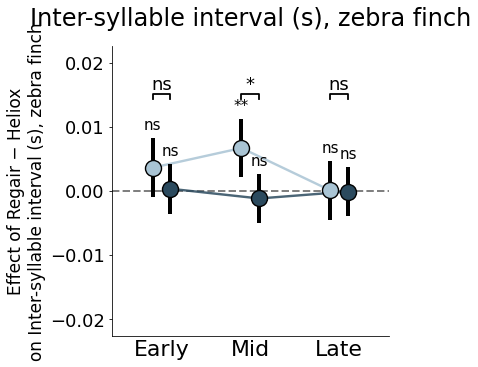

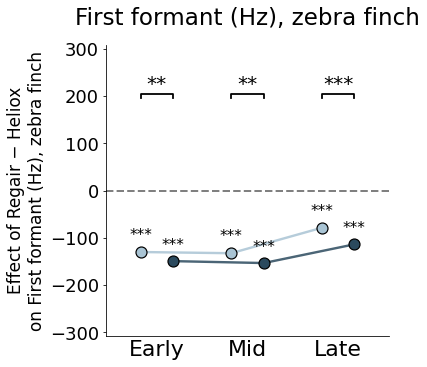

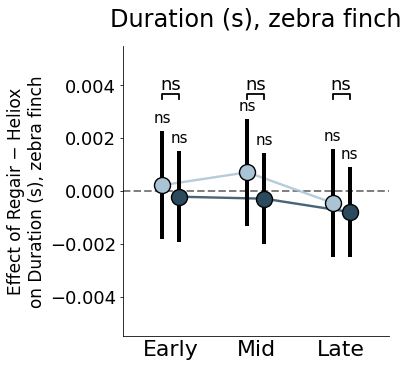

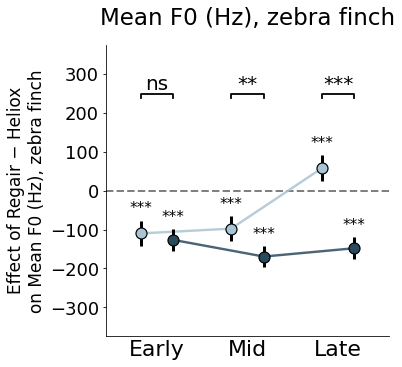

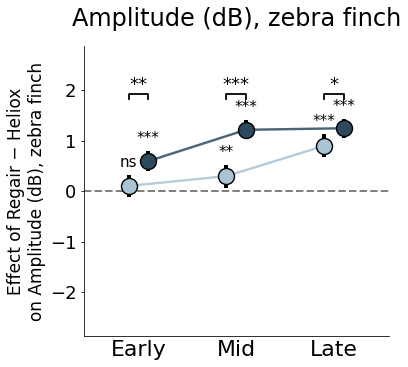

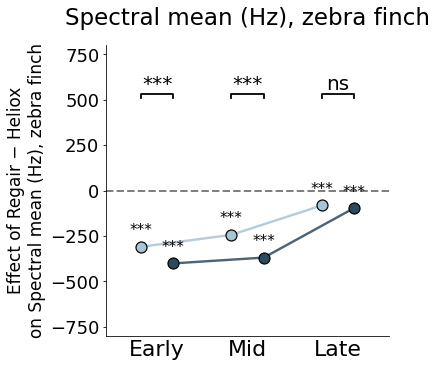

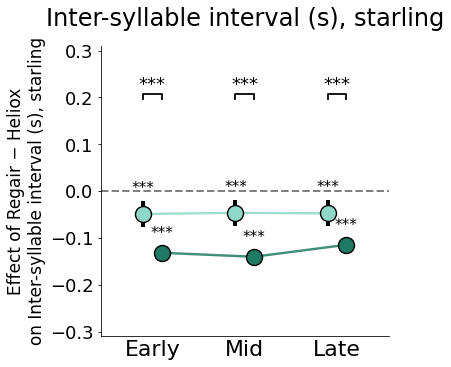

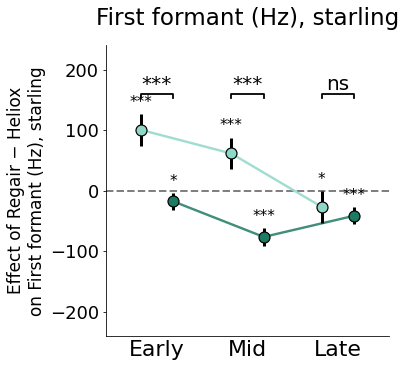

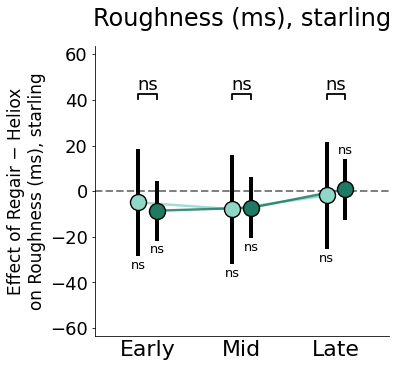

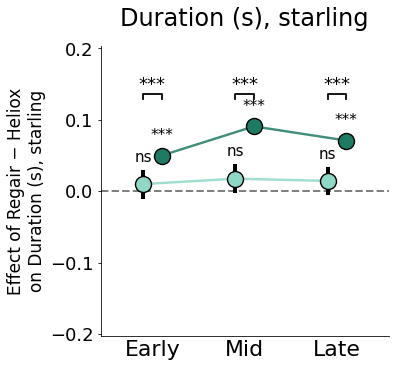

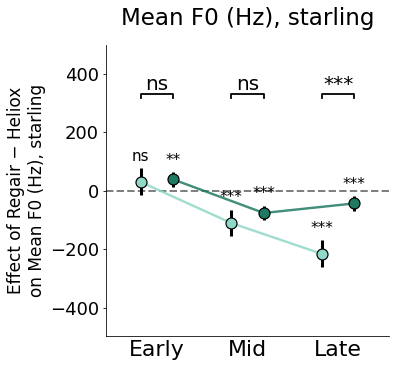

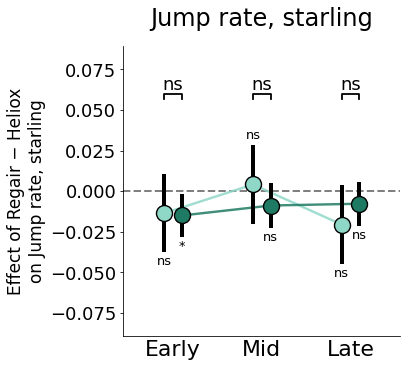

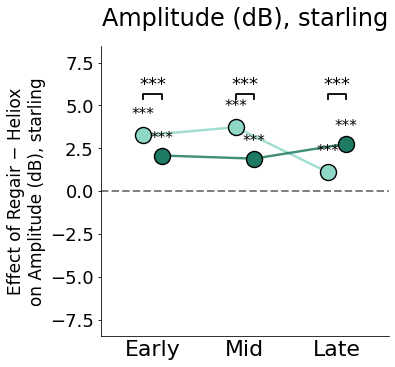

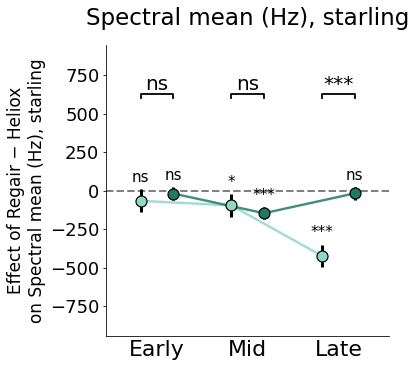

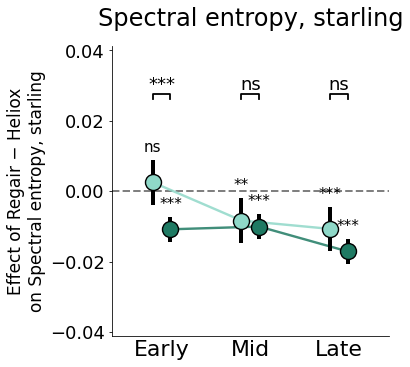

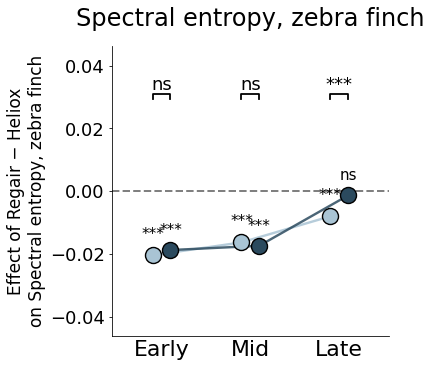

zebra finch entS: 6 birds, 68392 rows
    species feature             contrast estimate     SE      z       P stars
zebra finch    entS     Early, first day  -0.0204 0.0014 -14.74 3.8e-49   ***
zebra finch    entS    Early, later days  -0.0188 0.0012 -16.11 2.3e-58   ***
zebra finch    entS Early: first − later  -0.0016 0.0018  -0.90    0.37    ns
zebra finch    entS       Mid, first day  -0.0163 0.0014 -11.78 4.7e-32   ***
zebra finch    entS      Mid, later days  -0.0174 0.0012 -14.94 1.8e-50   ***
zebra finch    entS   Mid: first − later   0.0011 0.0018   0.59    0.55    ns
zebra finch    entS      Late, first day  -0.0080 0.0014  -5.79 6.9e-09   ***
zebra finch    entS     Late, later days  -0.0014 0.0012  -1.19    0.23    ns
zebra finch    entS  Late: first − later  -0.0066 0.0018  -3.65 0.00027   ***


In [8]:
# Cell 7: S7 A-O, one file per panel, plus one legend file per species
DAY_COLORS = {'starling': {'first': '#8fd8c8', 'later': '#1f7a63'},
              'zebra finch': {'first': '#a9c4d4', 'later': '#2b4a5e'}}
XD = dict(zip(EPOCHS, [0.0, 0.25, 0.5]))
# The three kinds of panel were first drawn in separate notebooks and differ slightly in
# marker size and spacing. Kept as they appear in the paper; for one look, use one row.
S7_FIGSIZE = (5.6, 5.2)        # inches; matches the proportions of the published panels (text size relative to the axes)
# Spectral entropy now comes from the BioSound table, but S7 O was drawn in the style of the syllable panels
STYLE_OF = {'entS': 'syllables'}
STYLE = {'syllables': dict(gap=0.025, ms=16, elw=4, mew=1.4, headroom=2.0, unit=0.06, star_fs=15, star_gap=0.6, bracket_fs=18, title_fs=24),
         'biosound':  dict(gap=0.045, ms=11, elw=3, mew=1.2, headroom=1.9, unit=0.05, star_fs=15, star_gap=0.6, bracket_fs=20, title_fs=23),
         'songs':     dict(gap=0.025, ms=16, elw=4, mew=1.4, headroom=2.0, unit=0.06, star_fs=13, star_gap=0.3, bracket_fs=18, title_fs=24)}


def plot_first_day(ax, result, colors, title, kind):
    s = STYLE[kind]
    offset = {'first': -s['gap'], 'later': s['gap']}
    c = {(e, g): contrast(result, effect_weights(result, e, g)) for e in EPOCHS for g in ['first', 'later']}
    for g in ['first', 'later']:
        ax.plot([XD[e] + offset[g] for e in EPOCHS], [c[e, g]['estimate'] for e in EPOCHS],
                '-', lw=2.4, color=colors[g], alpha=0.85, zorder=3)
        for e in EPOCHS:
            est, lo, hi = c[e, g]['estimate'], c[e, g]['CI_low'], c[e, g]['CI_high']
            ax.errorbar(XD[e] + offset[g], est, yerr=[[est - lo], [hi - est]], fmt='o', ms=s['ms'],
                        color=colors[g], capsize=0, elinewidth=s['elw'], ecolor='black', zorder=5,
                        markeredgecolor='black', markeredgewidth=s['mew'])
    ax.axhline(0, color='gray', ls='--', lw=2, zorder=0)
    extent = max(abs(min(v['CI_low'] for v in c.values())), abs(max(v['CI_high'] for v in c.values()))) or 1.0
    ax.set_ylim(-extent * s['headroom'], extent * s['headroom'])
    unit = extent * s['headroom'] * s['unit']
    for (e, g), v in c.items():
        # song panels put the star on the far side of the point from zero; the others always above
        below = kind == 'songs' and v['estimate'] < 0
        ax.text(XD[e] + offset[g], v['CI_low'] - unit * s['star_gap'] if below else v['CI_high'] + unit * s['star_gap'],
                stars(v['P']), ha='center', va='top' if below else 'bottom', fontsize=s['star_fs'])
    for e in EPOCHS:
        p = contrast(result, minus(effect_weights(result, e, 'first'), effect_weights(result, e, 'later')))['P']
        bracket(ax, XD[e] + offset['first'], XD[e] + offset['later'], extent + unit * 2.2, unit * 0.6, p,
                fontsize=s['bracket_fs'])
    ax.set_xlim(-0.14, 0.64)
    ax.set_xticks(list(XD.values()))
    ax.set_xticklabels(['Early', 'Mid', 'Late'], fontsize=22)
    ax.set_ylabel(f'Effect of Regair − Heliox\non {title}', fontsize=17)
    ax.set_title(title, fontsize=s['title_fs'], pad=20)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', labelsize=18)
    ax.tick_params(axis='x', length=0)


for p in PANELS:
    if p['figure'] == 'Fig. 5':
        continue
    fig, ax = plt.subplots(figsize=S7_FIGSIZE)
    plot_first_day(ax, p['result'], DAY_COLORS[p['species']], p['title'], STYLE_OF.get(p['column'], p['kind']))
    plt.tight_layout()
    save(fig, f"suppS7_{p['species'].replace(' ', '_')}_{p['column']}")
    plt.show()
    plt.close(fig)

for sp, colors in DAY_COLORS.items():
    fig = plt.figure(figsize=(3.4, 1.3))
    fig.legend(handles=[plt.Line2D([], [], marker='o', ls='-', ms=14, color=colors[g], markeredgecolor='black',
                                   markeredgewidth=1.2, label=label)
                        for g, label in [('first', 'First day'), ('later', 'Later days')]],
               loc='center', frameon=False, fontsize=18)
    save(fig, f"suppS7_legend_{sp.replace(' ', '_')}")
    plt.close(fig)

# ---- spectral entropy in zebra finches, first day against later days -----------------------
# S7 O shows starlings only; this is the same panel for zebra finches, so both species have amplitude
# (E, M) and spectral entropy. It is not a lettered panel and is not in Supp. Table S1, so its effects
# are printed here. To make it a panel, add it to S7 in Cell 2 instead.
EXTRA_S7 = [('zebra finch', 'biosound', 'entS')]       # species, kind of table, column
extra_rows = []
for sp, kind, column in EXTRA_S7:
    result, used = fit_first_day(DATA[f"{kind}_{sp.replace(' ', '_')}"], column, MIN_N_PER_DAY)
    title = f'{COLUMNS[column][0]}, {sp}'
    fig, ax = plt.subplots(figsize=S7_FIGSIZE)
    plot_first_day(ax, result, DAY_COLORS[sp], title, STYLE_OF.get(column, kind))
    plt.tight_layout()
    save(fig, f"suppS7_{sp.replace(' ', '_')}_{column}")
    plt.show()
    plt.close(fig)
    for e in EPOCHS:
        for g, name in [('first', 'first day'), ('later', 'later days')]:
            extra_rows.append(dict(species=sp, feature=column, contrast=f'{e.capitalize()}, {name}',
                                   **contrast(result, effect_weights(result, e, g))))
        extra_rows.append(dict(species=sp, feature=column, contrast=f'{e.capitalize()}: first − later',
                               **contrast(result, minus(effect_weights(result, e, 'first'),
                                                        effect_weights(result, e, 'later')))))
    print(f"{sp} {column}: {used['bird'].nunique()} birds, {len(used)} rows"
          + ('' if result.converged else '   [did not converge]'))

extra_s7 = pd.DataFrame(extra_rows)
extra_s7['stars'] = extra_s7['P'].map(stars)
print(extra_s7[['species', 'feature', 'contrast', 'estimate', 'SE', 'z', 'P', 'stars']].to_string(
    index=False, formatters={'estimate': '{:.4f}'.format, 'SE': '{:.4f}'.format, 'z': '{:.2f}'.format,
                             'P': '{:.2g}'.format}))

## 5. Supplementary Table S1

One row per number on a figure: each point (effect against zero) and each bracket
(change between epochs, or first day minus later days). `q_BH` is a Benjamini-Hochberg
correction within each figure x kind of contrast.

The last four columns are the bird-level check described in Methods: each bird's own
Regair minus Heliox difference of cell means, tested across birds with a one-sample
t-test. It uses raw means with no `day_number` adjustment, so read it for direction and
consistency across birds, not as a replication of the model.

In [9]:
# Cell 8: the statistics table
def bird_level(used, column, cell_a, cell_b=None):
    """Per-bird Regair minus Heliox in cell_a (minus the same in cell_b, if given).
    A cell is a dict such as {'epoch': 'late'} or {'epoch': 'mid', 'day_group': 'first'}."""
    def effect(cell):
        d = used
        for k, v in cell.items():
            d = d[d[k] == v]
        m = d.groupby(['bird', 'condition'], observed=True)[column].mean().unstack('condition')
        m = m.reindex(columns=['regair', 'heliox'])          # a cell can lack one condition entirely
        return m['regair'] - m['heliox']
    return (effect(cell_a) if cell_b is None else effect(cell_a) - effect(cell_b)).dropna()


rows = []
for p in PANELS:
    res, used, col = p['result'], p['used'], p['column']
    cells = []          # (kind of contrast, label, weights, bird-level cells)
    if p['figure'] == 'Fig. 5':
        for e in EPOCHS:
            cells.append(('Regair − Heliox vs 0', e.capitalize(), effect_weights(res, e), ({'epoch': e},)))
        for a, b in [('early', 'mid'), ('mid', 'late'), ('early', 'late')]:
            cells.append(('Change between epochs', f'{b.capitalize()} − {a.capitalize()}',
                          minus(effect_weights(res, b), effect_weights(res, a)), ({'epoch': b}, {'epoch': a})))
    else:
        for e in EPOCHS:
            for g, name in [('first', 'first day'), ('later', 'later days')]:
                cells.append(('Regair − Heliox vs 0', f'{e.capitalize()}, {name}', effect_weights(res, e, g),
                              ({'epoch': e, 'day_group': g},)))
            cells.append(('First day − later days', f'{e.capitalize()}: first − later',
                          minus(effect_weights(res, e, 'first'), effect_weights(res, e, 'later')),
                          ({'epoch': e, 'day_group': 'first'}, {'epoch': e, 'day_group': 'later'})))
    for kind, label, w, bird_cells in cells:
        c = contrast(res, w)
        per_bird = bird_level(used, col, *bird_cells)
        t, p_bird = stats.ttest_1samp(per_bird, 0.0) if len(per_bird) > 1 else (np.nan, np.nan)
        rows.append(dict(figure=p['figure'], panel=p['panel'], species=p['species'], feature=p['feature'],
                         unit=p['unit'], contrast_type=kind, contrast=label, **c,
                         n_birds=used['bird'].nunique(), n_obs=len(used), converged=bool(res.converged),
                         birds_same_sign=f"{int((np.sign(per_bird) == np.sign(c['estimate'])).sum())}/{len(per_bird)}",
                         bird_mean=per_bird.mean(), bird_t=t, bird_P=p_bird))

table = pd.DataFrame(rows)
table['stars'] = table['P'].map(stars)
table['q_BH'] = table.groupby(['figure', 'contrast_type'])['P'].transform(
    lambda p: multipletests(p, method='fdr_bh')[1])
table.to_csv(os.path.join(OUT_DIR, f'exposure_course_statistics{RUN_TAG}.csv'), index=False)

print(f'{len(table)} rows saved')
not_converged = table.loc[~table['converged'], ['figure', 'panel']].drop_duplicates()

with pd.option_context('display.width', 220, 'display.max_rows', 40):
    print(table.loc[table['figure'] == 'Fig. 5', ['panel', 'species', 'contrast', 'estimate', 'SE', 'z', 'P',
                                                  'stars', 'q_BH', 'birds_same_sign', 'bird_P']].round(4).to_string(index=False))

165 rows saved
panel     species     contrast  estimate     SE        z      P stars   q_BH birds_same_sign  bird_P
    I    starling        Early   -0.0590 0.0072  -8.1967 0.0000   *** 0.0000             5/6  0.2398
    I    starling          Mid   -0.0526 0.0073  -7.2369 0.0000   *** 0.0000             4/6  0.1091
    I    starling         Late   -0.0318 0.0082  -3.8627 0.0001   *** 0.0002             6/6  0.0131
    I    starling  Mid − Early    0.0064 0.0096   0.6673 0.5046    ns 0.6307             4/6  0.6388
    I    starling   Late − Mid    0.0208 0.0100   2.0753 0.0380     * 0.0712             3/6  0.9924
    I    starling Late − Early    0.0273 0.0100   2.7252 0.0064    ** 0.0161             3/6  0.6630
    J    starling        Early   -0.1120 0.0065 -17.2311 0.0000   *** 0.0000             5/6  0.0917
    J    starling          Mid   -0.1195 0.0068 -17.6285 0.0000   *** 0.0000             6/6  0.0445
    J    starling         Late   -0.0586 0.0076  -7.7536 0.0000   *** 0.0000

In [10]:
# Cell 9: the same table as LaTeX rows for Supplementary Table S1
# Writes the body only (panel headers and number rows). The caption, column header and the
# Fig. 5 G-H rows stay in the manuscript, which pulls this file in with \input{}.
def tex_scale(g, unit):
    """Seconds under 10 ms are shown in ms, other small quantities times 10^k, so that no
    estimate needs scientific notation. Decimals are fixed per panel."""
    biggest = np.nanmax(np.abs(np.r_[g['estimate'], g['CI_low'], g['CI_high']]))
    if unit == 's' and biggest < 0.01:
        factor, label = 1e3, 'ms'
    elif 0 < biggest < 0.01:
        k = int(-np.floor(np.log10(biggest)))
        factor, label = 10.0 ** k, (f'{unit}, ' if unit else '') + f'$\\times10^{{-{k}}}$'
    else:
        factor, label = 1.0, unit
    scaled = biggest * factor
    return factor, label, max(0, 2 - int(np.floor(np.log10(scaled)))) if scaled > 0 else 3


def tex_num(x, decimals):
    s = f'{x:.{decimals}f}'
    return f"${s.lstrip('-') if float(s) == 0 else s}$"


def tex_p(p, log10_p=None):
    if p <= 0:
        return r'$<10^{-300}$'
    if p >= 0.01:
        return f'${p:.3f}$'
    if p >= 1e-3:
        return f'${p:.4f}$'
    lp = log10_p if log10_p is not None else np.log10(p)
    e = int(np.floor(lp))
    m = 10 ** (lp - e)
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f'${m:.1f}\\times10^{{{e}}}$'


SECTION = {'Fig. 5': 'Across-exposure epochs (Fig.~5%s--%s)' % (FIG5[0][0].lower(), FIG5[-1][0].lower()),
           'Supp. Fig. S7': r'First day vs later days, by within-session epoch (Supplementary Fig.~\ref{fig:supp_first_day})'}
PANEL_REF = {'Fig. 5': lambda letter: f'Fig.~5{letter.lower()}',
             'Supp. Fig. S7': lambda letter: f'Supp.\\ Fig.~\\ref{{fig:supp_first_day}}{letter}'}

lines, current = [], None
for (figure, panel), g in table.groupby(['figure', 'panel'], sort=False):
    r0 = g.iloc[0]
    if figure != current:
        lines += ([r'\midrule'] if current else []) + [f'\\multicolumn{{8}}{{@{{}}l}}{{\\textit{{{SECTION[figure]}}}}}\\\\',
                                                       r'\addlinespace[2pt]']
        current = figure
    factor, unit_label, dec = tex_scale(g, r0['unit'])
    lines.append(f"\\multicolumn{{8}}{{@{{}}l}}{{\\textbf{{{PANEL_REF[figure](panel)}}}\\quad "
                 f"{r0['feature']}{f' ({unit_label})' if unit_label else ''}, {r0['species']}}}\\\\*")
    previous = None
    for _, r in g.iterrows():
        if figure == 'Fig. 5':
            if r['contrast_type'].startswith('Change') and previous == 'Regair − Heliox vs 0':
                lines.append(r'\cmidrule(l){1-8}')         # effects above, changes below
            previous = r['contrast_type']
        else:
            epoch = r['contrast'].split(',')[0].split(':')[0]
            if previous is not None and epoch != previous:
                lines.append(r'\addlinespace[3pt]')        # keep each epoch's three rows together
            previous = epoch
        label = r['contrast'].replace('−', '$-$')
        lines.append(f"\\quad {label} & {tex_num(r['estimate'] * factor, dec)} & {tex_num(r['SE'] * factor, dec)} & "
                     f"{tex_num(r['CI_low'] * factor, dec)}, {tex_num(r['CI_high'] * factor, dec)} & ${r['z']:.2f}$ & "
                     f"{tex_p(r['P'], r['log10_P'])} & {r['stars']} & {tex_p(r['q_BH'])} \\\\")
    lines.append(r'\addlinespace[4pt]')

tex_path = os.path.join(OUT_DIR, f'supp_table_S1_rows{RUN_TAG}.tex')
with open(tex_path, 'w') as f:
    f.write('\n'.join(lines) + '\n')
print(f'{len(table)} table rows written to {tex_path}')

165 table rows written to /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/supp_table_S1_rows.tex


In [11]:
# Cell 10: diagnostic. Each bird's own Regair - Heliox effect by epoch, for Fig. 5 I-M
# Why this cell: the Fig. 5 models are fit to every syllable (or song), so a bird with many rows
# pulls the estimate toward itself; the random intercept for bird does not even that out. This
# prints every bird's own effect next to the model's, so we can see whether the pattern in the
# figure is shared across birds or carried by one or two of them. Nothing is refit or saved.
# Run after Cell 5 (it reads PANELS).
for p in PANELS:
    if p['figure'] != 'Fig. 5':
        continue
    used, col = p['used'], p['column']
    # seconds are shown in ms so small zebra finch effects do not print as 0.000
    scale, unit = (1e3, 'ms') if p['unit'] == 's' else (1.0, p['unit'])

    # raw cell means, one per bird x epoch x condition, then Regair - Heliox within bird
    means = used.groupby(['bird', 'epoch', 'condition'], observed=True)[col].mean().unstack('condition')
    effect = (means['regair'] - means['heliox']).unstack('epoch').reindex(columns=EPOCHS) * scale
    effect['late - early'] = effect['late'] - effect['early']

    # the model's own numbers, for comparison (these are what the figure shows)
    model = {e: contrast(p['result'], effect_weights(p['result'], e))['estimate'] * scale for e in EPOCHS}
    model['late - early'] = model['late'] - model['early']

    # share of rows: how much of the model's data each bird supplies
    rows = used.groupby('bird').size()
    out = effect.copy()
    out.insert(0, 'share of rows', (rows / rows.sum()).reindex(out.index).map('{:.0%}'.format))
    out.loc['mean of birds'] = ['', *effect.mean()]
    out.loc['model (row-weighted)'] = ['', *[model[c] for c in effect.columns]]

    # how many birds move the same way as the model, column by column
    agree = {c: f"{int((np.sign(effect[c].dropna()) == np.sign(model[c])).sum())}/{effect[c].notna().sum()}"
             for c in effect.columns}
    out.loc['birds agreeing with model'] = ['', *[agree[c] for c in effect.columns]]

    print(f"\nFig. 5{p['panel']}  {p['species']}, {p['feature']}  (Regair - Heliox{', ' + unit if unit else ''})")
    print(out.to_string(float_format=lambda v: f'{v:.2f}' if unit == 'ms' else f'{v:.4f}'))


Fig. 5I  starling, JSD vs own-bird regair baseline  (Regair - Heliox)
epoch                     share of rows   early     mid    late late - early
bird                                                                        
s_b1349h_23                         21% -0.0130  0.0040 -0.0242      -0.0113
s_b1354_25                          39% -0.1084 -0.1059 -0.0836       0.0249
s_b1364_25                          17% -0.0194 -0.0475 -0.0159       0.0035
s_b1481h_24                          5%  0.0519 -0.0892 -0.0954      -0.1473
s_b1484h_24                         10% -0.1568 -0.1382 -0.0852       0.0716
s_b1556h_24                          7% -0.0039  0.0449 -0.0288      -0.0248
mean of birds                           -0.0416 -0.0553 -0.0555      -0.0139
model (row-weighted)                    -0.0590 -0.0526 -0.0318       0.0273
birds agreeing with model                   5/6     4/6     6/6          3/6

Fig. 5J  starling, Inter-syllable interval  (Regair - Heliox, ms)
epoch          

In [12]:
# Cell 11: bird-weighted refit of the Fig. 5 I-M models
# Why this cell: Cell 10 showed that the syllable-level models follow the birds with the most rows.
# Here every bird counts once. Each bird's rows are first averaged to one value per epoch and
# condition (36 values for 6 birds), and the same model as Fig. 5 is fit to those averages:
# value ~ epoch * condition + day_number + (1 | bird), with day_number averaged the same way.
# The contrasts are read off exactly as in Cell 6, so the two columns below are directly comparable.
# Caution: with 36 values the Wald z test is generous; treat P near 0.05 as borderline.
# Run after Cell 5. Nothing is saved.
CHANGES = [('early', 'mid'), ('mid', 'late'), ('early', 'late')]
bird_weighted = []
for p in PANELS:
    if p['figure'] != 'Fig. 5':
        continue
    used, col = p['used'], p['column']
    scale, unit = (1e3, 'ms') if p['unit'] == 's' else (1.0, p['unit'])

    # one row per bird x epoch x condition: the mean of the metric and of day_number in that cell
    cells = (used.groupby(['bird', 'epoch', 'condition'], observed=True)[[col, 'day_number']]
                 .mean().reset_index())
    cells['epoch'] = pd.Categorical(cells['epoch'], categories=EPOCHS)
    cells['condition'] = pd.Categorical(cells['condition'], categories=['regair', 'heliox'])
    res = fit_quietly(f"{col} ~ C(epoch, Treatment('early')) * condition + day_number", cells)

    # the same contrasts from both fits: each epoch against zero, then the change between epochs
    wanted = [(e.capitalize(), lambda r, e=e: effect_weights(r, e)) for e in EPOCHS]
    wanted += [(f'{b.capitalize()} - {a.capitalize()}',
                lambda r, a=a, b=b: minus(effect_weights(r, b), effect_weights(r, a))) for a, b in CHANGES]
    for label, weights in wanted:
        bw, rw = contrast(res, weights(res)), contrast(p['result'], weights(p['result']))
        bird_weighted.append(dict(panel=p['panel'], species=p['species'], feature=p['feature'], unit=unit,
                                  contrast=label, bw_est=bw['estimate'] * scale, bw_SE=bw['SE'] * scale,
                                  bw_z=bw['z'], bw_P=bw['P'], bw_sig=stars(bw['P']),
                                  rw_est=rw['estimate'] * scale, rw_sig=stars(rw['P']),
                                  n_cells=len(cells), converged=bool(res.converged)))

bird_weighted = pd.DataFrame(bird_weighted)
for (panel, species, feature, unit), g in bird_weighted.groupby(['panel', 'species', 'feature', 'unit'], sort=False):
    print(f"\nFig. 5{panel}  {species}, {feature}  (Regair - Heliox{', ' + unit if unit else ''}); "
          f"{g['n_cells'].iloc[0]} bird x epoch x condition means"
          + ('' if g['converged'].all() else '   [did not converge]'))
    show = g[['contrast', 'bw_est', 'bw_SE', 'bw_z', 'bw_P', 'bw_sig', 'rw_est', 'rw_sig']].rename(columns={
        'bw_est': 'bird-weighted', 'bw_SE': 'SE', 'bw_z': 'z', 'bw_P': 'P', 'bw_sig': 'sig',
        'rw_est': 'row-weighted (Fig. 5)', 'rw_sig': 'sig (Fig. 5)'})
    digits = 2 if unit == 'ms' else 4
    print(show.to_string(index=False, formatters={'bird-weighted': f'{{:.{digits}f}}'.format, 'SE': f'{{:.{digits}f}}'.format,
                                                  'z': '{:.2f}'.format, 'P': '{:.3g}'.format,
                                                  'row-weighted (Fig. 5)': f'{{:.{digits}f}}'.format}))


Fig. 5I  starling, JSD vs own-bird regair baseline  (Regair - Heliox); 36 bird x epoch x condition means
    contrast bird-weighted     SE     z      P sig row-weighted (Fig. 5) sig (Fig. 5)
       Early       -0.0436 0.0228 -1.92 0.0551  ns               -0.0590          ***
         Mid       -0.0578 0.0231 -2.50 0.0123   *               -0.0526          ***
        Late       -0.0615 0.0272 -2.26 0.0237   *               -0.0318          ***
 Mid - Early       -0.0142 0.0313 -0.45  0.651  ns                0.0064           ns
  Late - Mid       -0.0037 0.0326 -0.11   0.91  ns                0.0208            *
Late - Early       -0.0179 0.0330 -0.54  0.588  ns                0.0273           **

Fig. 5J  starling, Inter-syllable interval  (Regair - Heliox, ms); 36 bird x epoch x condition means
    contrast bird-weighted    SE     z       P sig row-weighted (Fig. 5) sig (Fig. 5)
       Early        -49.00 29.60 -1.66  0.0978  ns               -111.98          ***
         Mid      